# Chapter 23: Adam, AdamW and clipping

Checks [chapter 23](../../book/23-adam-and-clipping.md). The model is as small as the theorems: **one real weight at a time**
(or a short vector of weights) with a quadratic loss `strength * weight^2 / 2`, which is a model linear in its weights.
Adam is the memoryless form of the chapter, `gradient / sqrt(gradient^2)`, with no averages and no small constant.
Everything is NumPy in float64, seeded. These are numerical checks of the step rules, not proofs. A number is called *run* when it comes out of iterating a rule on a weight, and *from the formula* when it comes from evaluating one step or one identity. Nothing here is a fit to data or a training run on a dataset. Checks that the code forces are printed as `[by construction, cannot fail]` and are not evidence. the proofs are in `StepRules.lean` and
`AdamW.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report as report_check, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 23
COUNTS = {"could fail and passed": 0, "by construction": 0}


def report(label, passed, detail=""):
    """A check that could fail. It stops the notebook if it does, and is counted if it passes."""
    report_check(label, passed, detail)
    COUNTS["could fail and passed"] += 1


def note_by_construction(text):
    """A line that holds because of how the code is written. It is not evidence and is not counted as a pass."""
    COUNTS["by construction"] += 1
    print("[by construction, cannot fail] " + text)


def take_adam_step(gradient):
    """gradient / sqrt(gradient^2), with 0 / 0 read as 0, as in the Lean file."""
    gradient = np.asarray(gradient, dtype=float)
    size = np.sqrt(gradient ** 2)
    return np.divide(gradient, size, out=np.zeros_like(gradient), where=size > 0)


def take_plain_step(learning_rate, gradient, weight):
    return weight - learning_rate * gradient


def take_sign_step(learning_rate, gradient, weight):
    return weight - learning_rate * take_adam_step(gradient)


def clip(limit, gradient):
    """min(1, limit / norm) * gradient."""
    length = np.linalg.norm(gradient)
    if length == 0.0:
        return gradient
    return min(1.0, limit / length) * gradient


def take_adam_l2_step(learning_rate, decay, gradient, weight):
    return weight - learning_rate * take_adam_step(gradient + decay * weight)


def take_adamw_step(learning_rate, decay, gradient, weight):
    return weight - learning_rate * take_adam_step(gradient) - learning_rate * decay * weight


def count_steps_to_close(rule, strength, start_gap, target_gap, learning_rate, limit_steps=100_000):
    """Steps until |gap| <= target_gap, for a direction whose gradient is strength * gap. None if never."""
    gap = start_gap
    for step_count in range(limit_steps + 1):
        if abs(gap) <= target_gap:
            return step_count
        gap = rule(learning_rate, strength * gap, gap)
        if abs(gap) > 1e12:
            return None
    return None

## Claim 1: the memoryless Adam step is the sign of the gradient (`adam_step_is_the_sign_of_the_gradient`, `adam_step_ignores_the_loss_scale`, `adam_moves_every_coordinate_the_same_distance`)

Prediction: for 10 000 gradients spread over 12 orders of magnitude, both signs and exact zeros, the step equals
minus one, zero or one, the sign, to rounding error. Multiplying the loss by a positive number (here by factors from
1e-6 to 1e6) changes the step by nothing, and every coordinate with a gradient moves by exactly 1. The check would fail
if the step carried any trace of the size of the gradient. Control: the plain gradient step `learning_rate * gradient`
over the same gradients, whose size varies by the same twelve orders of magnitude.

In [2]:
generator = np.random.default_rng(SEED)
magnitudes = 10.0 ** generator.uniform(-6, 6, size=10_000)
gradients = magnitudes * generator.choice([-1.0, 1.0], size=10_000)
gradients[:50] = 0.0                                   # exact zeros

steps = take_adam_step(gradients)
worst_sign_gap = float(np.abs(steps - np.sign(gradients)).max())
scale_factors = 10.0 ** generator.uniform(-6, 6, size=10_000)
worst_scale_gap = float(np.abs(take_adam_step(scale_factors * gradients) - steps).max())
nonzero = gradients != 0.0
worst_size_gap = float(np.abs(np.abs(steps[nonzero]) - 1.0).max())
plain_sizes = np.abs(0.1 * gradients)
plain_spread = float(plain_sizes.max() / plain_sizes[nonzero].min())

report("the Adam step equals the sign of the gradient, 10 000 gradients over 12 decades",
       worst_sign_gap < 1e-12, f"largest gap {worst_sign_gap:.1e}")
report("multiplying the loss by a positive number changes no step", worst_scale_gap < 1e-12,
       f"largest change {worst_scale_gap:.1e}")
note_by_construction(f"every coordinate with a gradient moves by exactly 1: follows from the sign check above (largest gap {worst_size_gap:.1e}); not evidence")
report("control: the plain gradient step varies in size by the same factor as the gradients", plain_spread > 1e10,
       f"largest over smallest step {plain_spread:.1e}")

[PASS] the Adam step equals the sign of the gradient, 10 000 gradients over 12 decades  (largest gap 0.0e+00)
[PASS] multiplying the loss by a positive number changes no step  (largest change 0.0e+00)
[by construction, cannot fail] every coordinate with a gradient moves by exactly 1: follows from the sign check above (largest gap 0.0e+00); not evidence
[PASS] control: the plain gradient step varies in size by the same factor as the gradients  (largest over smallest step 1.0e+12)


## Claim 2: a gap closes by `learning_rate` per step, whatever the strength (`sign_step_closes_a_gap_by_the_learning_rate`)

The chapter's hand example: a gap of 3, `learning_rate = 0.5`. Prediction: the sign rule takes exactly 6 steps to reach
zero for every strength, here 0.01, 1 and 100, and each step removes exactly 0.5 from `|gap|` while `|gap| >= 0.5`.
The claim fails if any strength gives a different count. Control: plain gradient descent on the same directions. The
chapter predicts strength 100 blows up (factor `1 - 0.5 * 100 = -49`) and strength 0.01 still has a gap near 2.9 after 6 steps
(factor 0.995). The cell also measures how long plain descent needs to bring the gap below the learning rate, to put a number on
the chapter's argued remark that the sign rule removes the wait for weak directions.

In [3]:
LEARNING_RATE = 0.5
START_GAP = 3.0
sign_counts = {}
largest_step_error = 0.0
for strength in (0.01, 1.0, 100.0):
    gap = START_GAP
    count = 0
    while abs(gap) > 0:
        new_gap = float(take_sign_step(LEARNING_RATE, strength * gap, gap))
        if abs(gap) >= LEARNING_RATE:
            largest_step_error = max(largest_step_error, abs(abs(new_gap) - (abs(gap) - LEARNING_RATE)))
        gap = new_gap
        count += 1
    sign_counts[strength] = count
report("the sign rule closes a gap of 3 in 6 steps for strengths 0.01, 1 and 100",
       set(sign_counts.values()) == {6}, f"steps {sign_counts}")
note_by_construction(f"each step removes exactly learning_rate from the gap (largest error {largest_step_error:.1e}): the sign has size 1, so this restates the sign rule; not evidence")

plain_weak_gap = START_GAP
for _ in range(6):
    plain_weak_gap = take_plain_step(LEARNING_RATE, 0.01 * plain_weak_gap, plain_weak_gap)
plain_strong_gap = START_GAP
for _ in range(6):
    plain_strong_gap = take_plain_step(LEARNING_RATE, 100.0 * plain_strong_gap, plain_strong_gap)
report("control: plain descent leaves a gap of about 2.9 after 6 steps at strength 0.01",
       2.85 < plain_weak_gap < 2.95, f"gap {plain_weak_gap:.4f}")
report("control: plain descent blows up at strength 100", abs(plain_strong_gap) > 1e9, f"gap {plain_strong_gap:.2e}")

steps_plain_weak = count_steps_to_close(take_plain_step, 0.01, START_GAP, LEARNING_RATE, LEARNING_RATE)
steps_sign_weak = count_steps_to_close(take_sign_step, 0.01, START_GAP, LEARNING_RATE, LEARNING_RATE)
report("to get within learning_rate of zero, plain descent at strength 0.01 needs many more steps than the sign rule",
       steps_plain_weak is not None and steps_plain_weak > 50 * steps_sign_weak,
       f"plain {steps_plain_weak} steps, sign {steps_sign_weak} steps")

[PASS] the sign rule closes a gap of 3 in 6 steps for strengths 0.01, 1 and 100  (steps {0.01: 6, 1.0: 6, 100.0: 6})
[by construction, cannot fail] each step removes exactly learning_rate from the gap (largest error 0.0e+00): the sign has size 1, so this restates the sign rule; not evidence
[PASS] control: plain descent leaves a gap of about 2.9 after 6 steps at strength 0.01  (gap 2.9111)
[PASS] control: plain descent blows up at strength 100  (gap 4.15e+10)
[PASS] to get within learning_rate of zero, plain descent at strength 0.01 needs many more steps than the sign rule  (plain 358 steps, sign 5 steps)


## Claim 3: decay inside Adam is rescaled away, AdamW keeps it (`decay_inside_adam_is_rescaled_away`, `decay_inside_adam_moves_every_weight_alike`, `scaling_the_loss_inside_adam_is_scaling_the_decay`, `adamw_shrinks_then_steps`, `adamw_with_no_gradient_after_many_steps`, `adamw_decay_does_not_depend_on_loss_scale`)

Prediction, with `decay = 0.5` and `learning_rate = 0.1` and no loss gradient. Inside Adam, a weight of 4 and a weight of 0.1
each lose exactly 0.1, so the small one is gone after one step. Over decays from 0.001 to 1000 the weight always moves by
exactly `learning_rate`. A larger loss is the same as a weaker decay (`scaling_the_loss_inside_adam_is_scaling_the_decay`). AdamW multiplies each weight by
`1 - 0.1 * 0.5 = 0.95`, so after 10 steps each weight is `0.95 ** 10`, about 0.60, of what it was and after 20 steps `0.95 ** 20`,
about 0.36. `adamw_shrinks_then_steps`: with a gradient, the step equals shrink then Adam's step. `adamw_decay_does_not_depend_on_loss_scale`: scaling the loss gradient
leaves the shrink unchanged. Control for the inside form: plain gradient descent with an L2 penalty, where the pull does depend on
the weight, so a weight of 4 loses 40 times what a weight of 0.1 loses.

In [4]:
LEARNING_RATE, DECAY = 0.1, 0.5
inside_losses = [4.0 - take_adam_l2_step(LEARNING_RATE, DECAY, 0.0, 4.0), 0.1 - take_adam_l2_step(LEARNING_RATE, DECAY, 0.0, 0.1)]
report("inside Adam, a weight of 4 and a weight of 0.1 both lose exactly 0.1 in a step",
       all(abs(loss - 0.1) < 1e-12 for loss in inside_losses), f"losses {[float(loss) for loss in inside_losses]}")
small_weight_after = float(take_adam_l2_step(LEARNING_RATE, DECAY, 0.0, 0.1))
report("inside Adam, the small weight is gone after one step", abs(small_weight_after) < 1e-12, f"weight {small_weight_after:.1e}")

generator = np.random.default_rng(SEED + 1)
decays = 10.0 ** np.linspace(-3, 3, 25)
worst_move_gap = 0.0
for decay in decays:
    for weight in generator.uniform(0.01, 5.0, size=20):
        gradient = float(generator.normal() * 3)
        if gradient + decay * weight != 0.0:
            moved = abs(weight - float(take_adam_l2_step(LEARNING_RATE, decay, gradient, weight)))
            worst_move_gap = max(worst_move_gap, abs(moved - LEARNING_RATE))
note_by_construction(f"inside Adam the weight moves by exactly learning_rate for decays 0.001 to 1000 (largest gap {worst_move_gap:.1e}): the step is the sign times learning_rate, which has size 1; not evidence")

worst_mul_gap = 0.0
for _ in range(2000):
    gradient, weight = generator.normal(size=2) * 3
    scale = 10.0 ** generator.uniform(-3, 3)
    stronger_loss = take_adam_l2_step(LEARNING_RATE, DECAY, scale * gradient, weight)
    weaker_decay = take_adam_l2_step(LEARNING_RATE, DECAY / scale, gradient, weight)
    worst_mul_gap = max(worst_mul_gap, abs(float(stronger_loss) - float(weaker_decay)))
note_by_construction(f"inside Adam, scaling the loss by c is the same as dividing the decay by c (largest gap {worst_mul_gap:.1e}): the sign is unchanged by a positive factor, which is claim 1; not evidence")

weights = np.array([4.0, 0.1, 1.0, -2.0])
weights_after_ten = weights.copy()
for _ in range(10):
    weights_after_ten = take_adamw_step(LEARNING_RATE, DECAY, np.zeros(4), weights_after_ten)
weights_after_twenty = weights.copy()
for _ in range(20):
    weights_after_twenty = take_adamw_step(LEARNING_RATE, DECAY, np.zeros(4), weights_after_twenty)
fraction_ten = weights_after_ten / weights
fraction_twenty = weights_after_twenty / weights
note_by_construction(f"AdamW with a zero gradient leaves 0.95 ** 10 = {0.95 ** 10:.4f} of every weight after 10 steps and 0.95 ** 20 = {0.95 ** 20:.4f} after 20 (exact iteration of the rule, fractions {np.round(fraction_ten, 4)} and {np.round(fraction_twenty, 4)}): each step is literally weight * (1 - learning_rate * decay), so this compares an iterated formula with its closed form; not evidence")

worst_eq_gap = 0.0
worst_adamw_mul_gap = 0.0
for _ in range(2000):
    learning_rate, decay, gradient, weight = generator.normal(size=4) * 2
    shrunk_then_stepped = (1 - learning_rate * decay) * weight - learning_rate * float(take_adam_step(gradient))
    worst_eq_gap = max(worst_eq_gap, abs(float(take_adamw_step(learning_rate, decay, gradient, weight)) - shrunk_then_stepped))
    scale = 10.0 ** generator.uniform(-3, 3)
    worst_adamw_mul_gap = max(worst_adamw_mul_gap, abs(float(take_adamw_step(learning_rate, decay, scale * gradient, weight))
                                                       - float(take_adamw_step(learning_rate, decay, gradient, weight))))
note_by_construction(f"AdamW is the shrink by 1 - learning_rate * decay, then Adam's step: the function is written as that sum, collected (largest gap {worst_eq_gap:.1e}); not evidence")
report("AdamW: scaling the loss gradient changes nothing, the decay is not rescaled", worst_adamw_mul_gap < 1e-9,
       f"largest change {worst_adamw_mul_gap:.1e}")

plain_losses = [weight - take_plain_step(LEARNING_RATE, DECAY * weight, weight) for weight in (4.0, 0.1)]
report("control (from the formula): plain descent with an L2 penalty makes a weight of 4 lose far more than a weight of 0.1",
       plain_losses[0] > 10 * plain_losses[1], f"losses {plain_losses}, ratio {plain_losses[0] / plain_losses[1]:.1f}")

[PASS] inside Adam, a weight of 4 and a weight of 0.1 both lose exactly 0.1 in a step  (losses [0.10000000000000009, 0.1])
[PASS] inside Adam, the small weight is gone after one step  (weight 0.0e+00)
[by construction, cannot fail] inside Adam the weight moves by exactly learning_rate for decays 0.001 to 1000 (largest gap 3.6e-16): the step is the sign times learning_rate, which has size 1; not evidence
[by construction, cannot fail] inside Adam, scaling the loss by c is the same as dividing the decay by c (largest gap 0.0e+00): the sign is unchanged by a positive factor, which is claim 1; not evidence
[by construction, cannot fail] AdamW with a zero gradient leaves 0.95 ** 10 = 0.5987 of every weight after 10 steps and 0.95 ** 20 = 0.3585 after 20 (exact iteration of the rule, fractions [0.5987 0.5987 0.5987 0.5987] and [0.3585 0.3585 0.3585 0.3585]): each step is literally weight * (1 - learning_rate * decay), so this compares an iterated formula with its closed form; not evidence
[b

## Claim 4: clipping caps the length of a gradient and the travel of the weights (`clipped_gradient_is_at_most_the_limit`, `gradient_within_the_limit_is_left_alone`, `clipping_caps_the_travel`)

Prediction: for 5000 random gradients in 5 dimensions with lengths from 0.001 to 1000 and `limit = 2`, the clipped length is
at most 2, and every gradient with length at most 2 is left unchanged. Over 100 steps with `learning_rate = 0.1` the travel
`||sum of the steps||` is at most `100 * (0.1 * 2) = 20` for random gradient sequences, and the bound is tight: gradients that
all point the same way reach 20. The chapter's check-yourself case, `limit = 5`, `learning_rate = 0.2`, 100 steps, caps travel
at 100, so a fit at distance 250 is out of reach. The claim fails if any travel exceeds the cap. Control: the same random
gradients without clipping travel much further than the cap.

In [5]:
generator = np.random.default_rng(SEED + 2)
LIMIT, LEARNING_RATE, STEP_COUNT = 2.0, 0.1, 100
directions = generator.standard_normal((5000, 5))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)
lengths = 10.0 ** generator.uniform(-3, 3, size=5000)
many_gradients = directions * lengths[:, None]
clipped = np.array([clip(LIMIT, gradient) for gradient in many_gradients])
clipped_lengths = np.linalg.norm(clipped, axis=1)
within = lengths <= LIMIT
report("a clipped gradient is never longer than the limit", clipped_lengths.max() <= LIMIT + 1e-12,
       f"longest {clipped_lengths.max():.6f} of {LIMIT}")
note_by_construction(f"a gradient within the limit is left alone ({int(within.sum())} of 5000 gradients within the limit, largest change {np.abs(clipped[within] - many_gradients[within]).max():.1e}): this is the definition of clip; not evidence")


def measure_travel(gradient_sequence, learning_rate, limit):
    total = np.zeros(gradient_sequence.shape[1])
    for gradient in gradient_sequence:
        total += learning_rate * (clip(limit, gradient) if limit is not None else gradient)
    return float(np.linalg.norm(total))


travel_cap = STEP_COUNT * (LEARNING_RATE * LIMIT)
clipped_travels, plain_travels = [], []
for _ in range(200):
    sequence = generator.standard_normal((STEP_COUNT, 5)) * 10.0 ** generator.uniform(-2, 3, size=(STEP_COUNT, 1))
    clipped_travels.append(measure_travel(sequence, LEARNING_RATE, LIMIT))
    plain_travels.append(measure_travel(sequence, LEARNING_RATE, None))
aligned = np.tile(np.array([[300.0, -400.0, 0.0, 0.0, 0.0]]), (STEP_COUNT, 1))
aligned_travel = measure_travel(aligned, LEARNING_RATE, LIMIT)
report("travel after 100 clipped steps is at most 100 * (0.1 * 2) = 20, for 200 random sequences",
       max(clipped_travels) <= travel_cap + 1e-9, f"largest travel {max(clipped_travels):.3f}")
report("the cap is tight: 100 aligned gradients of length 500 reach it", abs(aligned_travel - travel_cap) < 1e-9,
       f"travel {aligned_travel:.6f}")
report("control: without clipping the same sequences travel beyond the cap",
       max(plain_travels) > travel_cap,
       f"largest unclipped travel {max(plain_travels):.0f} against cap {travel_cap:.0f}, ratio {max(plain_travels) / travel_cap:.1f}")

# Harder candidates for the travel bound (own seeded generator, so the numbers above do not change):
# gradients along a slowly rotating direction, and gradients aligned for a random fraction of the steps.
hard_generator = np.random.default_rng(SEED + 20)
HARD_LENGTH = 500.0
hard_travels = {"rotating": [], "partly aligned": []}
for _ in range(300):
    first = hard_generator.standard_normal(5)
    first /= np.linalg.norm(first)
    second = hard_generator.standard_normal(5)
    second -= (second @ first) * first
    second /= np.linalg.norm(second)
    turn_per_step = 10.0 ** hard_generator.uniform(-3, -0.5)
    angles = turn_per_step * np.arange(STEP_COUNT)
    rotating = HARD_LENGTH * (np.cos(angles)[:, None] * first + np.sin(angles)[:, None] * second)
    hard_travels["rotating"].append(measure_travel(rotating, LEARNING_RATE, LIMIT))
    fraction_aligned = hard_generator.uniform(0.5, 1.0)
    random_part = hard_generator.standard_normal((STEP_COUNT, 5))
    random_part *= HARD_LENGTH / np.linalg.norm(random_part, axis=1, keepdims=True)
    is_aligned = hard_generator.uniform(size=STEP_COUNT) < fraction_aligned
    partly = np.where(is_aligned[:, None], HARD_LENGTH * first, random_part)
    hard_travels["partly aligned"].append(measure_travel(partly, LEARNING_RATE, LIMIT))
hard_largest = max(max(values) for values in hard_travels.values())
report("travel is at most the cap for 300 slowly rotating and 300 partly aligned sequences (clipped length 2 on every step)",
       hard_largest <= travel_cap + 1e-9,
       f"largest travel over cap: rotating {max(hard_travels['rotating']) / travel_cap:.5f}, partly aligned {max(hard_travels['partly aligned']) / travel_cap:.5f}")

check_cap = 100 * (0.2 * 5.0)
check_aligned = measure_travel(np.tile(np.array([[1000.0, 0.0, 0.0, 0.0, 0.0]]), (100, 1)), 0.2, 5.0)
report("limit 5, learning_rate 0.2: aligned gradients reach the cap of 100 and no more",
       abs(check_aligned - check_cap) < 1e-9,
       f"cap {check_cap:.0f}, best case reached {check_aligned:.1f}")
note_by_construction(f"so a fit at distance 250 is out of reach: the cap {check_cap:.0f} is below 250, steps needed at least {250 / (0.2 * 5.0):.0f}; arithmetic on constants, not evidence")

[PASS] a clipped gradient is never longer than the limit  (longest 2.000000 of 2.0)
[by construction, cannot fail] a gradient within the limit is left alone (2775 of 5000 gradients within the limit, largest change 0.0e+00): this is the definition of clip; not evidence
[PASS] travel after 100 clipped steps is at most 100 * (0.1 * 2) = 20, for 200 random sequences  (largest travel 3.374)
[PASS] the cap is tight: 100 aligned gradients of length 500 reach it  (travel 20.000000)
[PASS] control: without clipping the same sequences travel beyond the cap  (largest unclipped travel 1014 against cap 20, ratio 50.7)


[PASS] travel is at most the cap for 300 slowly rotating and 300 partly aligned sequences (clipped length 2 on every step)  (largest travel over cap: rotating 0.99958, partly aligned 1.00000)
[PASS] limit 5, learning_rate 0.2: aligned gradients reach the cap of 100 and no more  (cap 100, best case reached 100.0)
[by construction, cannot fail] so a fit at distance 250 is out of reach: the cap 100 is below 250, steps needed at least 250; arithmetic on constants, not evidence


## Figure: three rules on one landscape, and step size against gradient size

Written to `book/figures/23-three-step-rules.png`. The loss is `(100 * w1^2 + 0.01 * w2^2) / 2`: one strong and one weak
direction, starting at `(1, 3)`. Left, the paths of plain descent (grey, learning rate 0.015), the sign rule (purple,
learning rate 0.05) and clipped descent (blue, learning rate 0.015 with `limit = 20`). Right, the length of one step against
the length of the gradient for the three rules on a one-weight problem, with the clipping cap in green.
Prediction: plain descent moves `w2` almost not at all in 200 steps while the sign rule has crossed it, and the clipped step
equals the plain step for small gradients and stops at `learning_rate * limit`. Every point is computed here.

[PASS] plain descent has barely moved the weak weight after 200 steps; the sign rule has reached it  (weak weight: plain 2.911, sign 0.000, clipped 2.912; start 3.0)
[PASS] the clipped step is the plain step below the limit and stops at learning_rate * limit  (largest clipped step 0.300, cap 0.300)


wrote book/figures/23-three-step-rules.png


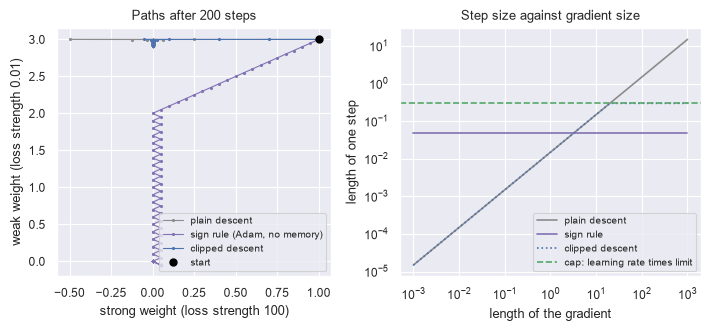

In [6]:
STRENGTHS = np.array([100.0, 0.01])
START = np.array([1.0, 3.0])
PATH_STEPS = 200
PLAIN_RATE, SIGN_RATE, CLIP_RATE, CLIP_LIMIT = 0.015, 0.05, 0.015, 20.0


def run_path(step_rule):
    weights = START.copy()
    path = [weights.copy()]
    for _ in range(PATH_STEPS):
        weights = step_rule(STRENGTHS * weights, weights)
        path.append(weights.copy())
    return np.array(path)


plain_path = run_path(lambda gradient, weights: weights - PLAIN_RATE * gradient)
sign_path = run_path(lambda gradient, weights: weights - SIGN_RATE * take_adam_step(gradient))
clip_path = run_path(lambda gradient, weights: weights - CLIP_RATE * clip(CLIP_LIMIT, gradient))

report("plain descent has barely moved the weak weight after 200 steps; the sign rule has reached it",
       abs(plain_path[-1, 1] - START[1]) < 0.05 * START[1] and abs(sign_path[-1, 1]) <= SIGN_RATE + 1e-12,
       f"weak weight: plain {plain_path[-1, 1]:.3f}, sign {sign_path[-1, 1]:.3f}, clipped {clip_path[-1, 1]:.3f}; start {START[1]}")

gradient_sizes = 10.0 ** np.linspace(-3, 3, 400)
plain_step_sizes = PLAIN_RATE * gradient_sizes
sign_step_sizes = np.array([SIGN_RATE * abs(float(take_adam_step(size))) for size in gradient_sizes])
clip_step_sizes = np.array([CLIP_RATE * np.linalg.norm(clip(CLIP_LIMIT, np.array([size]))) for size in gradient_sizes])
below_limit = gradient_sizes <= CLIP_LIMIT
report("the clipped step is the plain step below the limit and stops at learning_rate * limit",
       np.abs(clip_step_sizes[below_limit] - plain_step_sizes[below_limit]).max() < 1e-12
       and clip_step_sizes.max() <= CLIP_RATE * CLIP_LIMIT + 1e-12,
       f"largest clipped step {clip_step_sizes.max():.3f}, cap {CLIP_RATE * CLIP_LIMIT:.3f}")

figure, (left, right) = plt.subplots(1, 2, figsize=(7.2, 3.4), gridspec_kw={"width_ratios": [1, 1.1]})
for path, colour, name in ((plain_path, BEFORE, "plain descent"), (sign_path, MODEL, "sign rule (Adam, no memory)"),
                           (clip_path, NEAREST, "clipped descent")):
    left.plot(path[:, 0], path[:, 1], ".-", color=colour, markersize=2.5, linewidth=0.8, label=name)
left.plot(*START, "o", color="black", markersize=5, label="start")
left.set_xlabel("strong weight (loss strength 100)")
left.set_ylabel("weak weight (loss strength 0.01)")
left.set_title("Paths after 200 steps")
left.legend(loc="lower right", fontsize=7)

right.loglog(gradient_sizes, plain_step_sizes, color=BEFORE, label="plain descent")
right.loglog(gradient_sizes, sign_step_sizes, color=MODEL, label="sign rule")
right.loglog(gradient_sizes, clip_step_sizes, color=NEAREST, linestyle=":", label="clipped descent")
right.axhline(CLIP_RATE * CLIP_LIMIT, color=BOUND, linestyle="--", label="cap: learning rate times limit")
right.set_xlabel("length of the gradient")
right.set_ylabel("length of one step")
right.set_title("Step size against gradient size")
right.legend(loc="lower right", fontsize=7)
figure.tight_layout()
save_figure(figure, "23-three-step-rules")
plt.show()

In [7]:
print(f"checks that could fail and passed: {COUNTS['could fail and passed']}; printed as by construction, not counted: {COUNTS['by construction']}")

checks that could fail and passed: 19; printed as by construction, not counted: 8
